# Práctica 4. Primeros circuitos cuánticos con Qiskit

**Duración estimada:** 60–75 minutos   
**Herramientas:** Python, NumPy, Qiskit, Qiskit Aer y Matplotlib

> Completa las celdas marcadas con `TODO` y responde razonadamente en las celdas Markdown. Ejecuta al terminar **Kernel → Restart & Run All**.

## Objetivos

- Crear y visualizar circuitos de uno y dos qubits.
- Diferenciar qubits, bits clásicos, puertas y medidas.
- Preparar $|0\rangle$ y $|1\rangle$.
- Obtener amplitudes y probabilidades exactas con `Statevector`.
- Transpilar y ejecutar circuitos con `AerSimulator`.
- Obtener conteos, frecuencias e histogramas.
- Distinguir simulación exacta y muestreo.
- Interpretar el orden de bits de Qiskit.
- Comparar Qiskit con el formalismo matricial de NumPy.

## Entrega

Entrega este notebook con el nombre:

```text
04_primeros_circuitos_qiskit_apellidos_nombre.ipynb
```

Debe contener código ejecutado, circuitos dibujados, resultados, respuestas, pruebas y una conclusión final. No se aceptarán respuestas compuestas únicamente por código.

# Preparación del entorno

## Ejercicio 1. Instalación y comprobación

Si el entorno no dispone de las bibliotecas, descomenta y ejecuta la siguiente celda una sola vez. Reinicia después el kernel.

In [1]:
# Descomenta únicamente si necesitas instalar las dependencias.
%pip install qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
import qiskit_aer

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

np.set_printoptions(precision=5, suppress=True)

print(f"Qiskit version: {qiskit.__version__}")
print(f"Qiskit Aer version: {qiskit_aer.__version__}")
print(f"NumPy version: {np.__version__}")

Qiskit version: 2.6.0
Qiskit Aer version: 0.18.0
NumPy version: 2.4.6


### Responde

1. ¿Qué funciones aporta Qiskit?
    - QuantumCircuit, transpile, Statevector, AerSimulator y plot_histogram
2. ¿Para qué se utiliza Qiskit Aer?
    - Para simular circuitos cuánticos sin hardware real
3. ¿Por qué puede ser necesario reiniciar el kernel después de instalar?
    - Porque el kernel ya tiene precargados los módulos en memoria y al reiniciarlo importamos las versiones recién instaladas.
4. ¿Qué biblioteca permite comparar los circuitos con matrices?
    - Numpy

# Parte A. Construcción de circuitos

## Ejercicio 2. Circuito vacío de un qubit

Crea un circuito con un qubit, sin bits clásicos ni puertas. Muestra el circuito, el número de qubits y el número de bits clásicos. Visualízalo en texto y con Matplotlib.

   
q: 
   
Número de qubits: 1
Número de bits clásicos: 0


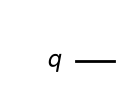

In [3]:
circuito_0 = QuantumCircuit(1)

print(circuito_0)
print(f"Número de qubits: {circuito_0.num_qubits}")
print(f"Número de bits clásicos: {circuito_0.num_clbits}")

display(circuito_0.draw("mpl"))

### Responde

1. ¿Qué estado tiene inicialmente el qubit?
    - $\ket0$
2. ¿Un circuito vacío carece de estado?
    - No. Aunque no tenga puertas, tiene estado inicial.
3. ¿Se ha ejecutado al construirlo?
    - No. Solo se han definido las operaciones que tiene que ejecutar.
4. ¿Qué diferencia existe entre construir y ejecutar?
    - Construir es hacer la lista de operaciones que tiene que ejecutar, mientras que ejecutar es simularlas para obtener resultados.
5. ¿Qué representa la línea horizontal?
    - El qubit y la linea de tiempo.

## Ejercicio 3. Circuito con un bit clásico
Crea un circuito con un qubit y un bit clásico, pero sin medidas. Consulta sus propiedades y visualízalo.

Número de qubits: 1
Número de bits clásicos: 1


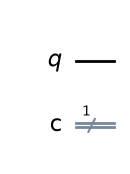

In [4]:
circuito_clasico = QuantumCircuit(1, 1)

print(f"Número de qubits: {circuito_clasico.num_qubits}")
print(f"Número de bits clásicos: {circuito_clasico.num_clbits}")

display(circuito_clasico.draw("mpl"))

### Responde

1. ¿Qué diferencia presenta respecto al circuito anterior?
    -   Tiene un bit clásico más y aparece una linea doble para representarlo
2. ¿Declarar un bit clásico mide automáticamente?
    - No, necesitariamos añadir `measure`
3. ¿Para qué se utilizará el bit clásico?
    - Para guardar el resultado de medida
4. ¿Puede encontrarse en superposición?
    - No, un bit clásico solo puede valer 1 o 0


## Ejercicio 4. Preparación de $|1\rangle$

Crea un circuito de un qubit, aplica $X$ al qubit 0 y visualízalo.

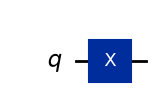

In [5]:
circuito_1 = QuantumCircuit(1)

circuito_1.x(0)
display(circuito_1.draw("mpl"))

### Responde

1. ¿Cuál es el estado inicial?
    - $\ket0$
2. ¿Qué transformación realiza $X$?
    - $X$ intercambia $\ket0$ y $\ket1$. Es como una puerta NOT
3. ¿Qué estado debe obtenerse?
    - $\ket1$
4. ¿Qué indica el argumento de `x(0)`?
    - El índice del qubit al que se aplica la puerta $X$
5. ¿Qué ocurriría al utilizar `x(1)` en este circuito?
    - Daría error porque este circuito solo tiene qubit 0


## Ejercicio 5. Dos aplicaciones de $X$
Construye y visualiza un circuito con dos puertas $X$ consecutivas sobre el mismo qubit. Predice el estado final antes de simularlo.

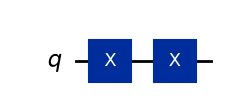

In [6]:
circuito_xx = QuantumCircuit(1)

circuito_xx.x(0)
circuito_xx.x(0)
display(circuito_xx.draw("mpl"))

### Responde

1. ¿Cuál debe ser el estado final?
    - $\ket0$ porque aplicamos un doble NOT a $\ket0$
2. ¿Qué relación se cumple entre $X^2$ y la identidad?
    - $X^2=I$ 
3. ¿Importa que ambas puertas actúen sobre el mismo qubit?
    - Si. Las puertas solo actuan sobre el qubit que tienen en argumento.
4. ¿Se aplican simultáneamente?
    - No, se aplican de izquierda a derecha.

# Parte B. Vectores de estado

## Ejercicio 6. Estado del circuito vacío

Obtén `Statevector.from_instruction(circuito_0)`. Muestra el objeto, `data`, sus tipos y la forma del array. Compáralo con $|0\rangle=(1,0)^T$.

In [7]:
estado_0 = Statevector.from_instruction(circuito_0)

ket_0_numpy = np.array([1, 0], dtype=complex)

print(f"Statevector: {estado_0}")
print(f"data: {estado_0.data}")
print(f"Tipo del estado_0': {type(estado_0)}")
print(f"Tipo de data: {type(estado_0.data)}")
print(f"Forma de data: {estado_0.data.shape}")
print(f"Coincide con |0>: {np.allclose(estado_0.data, ket_0_numpy)}")

Statevector: Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
data: [1.+0.j 0.+0.j]
Tipo del estado_0': <class 'qiskit.quantum_info.states.statevector.Statevector'>
Tipo de data: <class 'numpy.ndarray'>
Forma de data: (2,)
Coincide con |0>: True


### Responde

1. ¿Qué diferencia existe entre `Statevector` y `data`?
    - Statevector es el objeto de Qiskit mientras que data es el array de Numpy con las amplitudes
2. ¿Cuántas amplitudes contiene un qubit?
    - Dos. Una para $\ket0$ y otra para $\ket1$
3. ¿Por qué son complejas?
    - Porque pueden tener una fase asociada.
4. ¿Por qué se utiliza `np.allclose()`?
    - Para evitar errores de numeros en coma flotante y de redondeo.

## Ejercicio 7. Estado después de $X$
Obtén el vector de `circuito_1`. Muestra norma, amplitudes y probabilidades. Compáralo con $|1\rangle=(0,1)^T$.

In [8]:
estado_1 = Statevector.from_instruction(circuito_1)
ket_1_numpy = np.array([0, 1], dtype=complex)

print("Vector:", estado_1.data)
print("Norma:", np.linalg.norm(estado_1.data))
print("Amplitud de |0>:", estado_1.data[0])
print("Amplitud de |1>:", estado_1.data[1])
print("Probabilidades:", estado_1.probabilities())
print("Coincide con |1>:", np.allclose(estado_1.data, ket_1_numpy))

Vector: [0.+0.j 1.+0.j]
Norma: 1.0
Amplitud de |0>: 0j
Amplitud de |1>: (1+0j)
Probabilidades: [0. 1.]
Coincide con |1>: True


### Responde

1. ¿Qué amplitud tiene cada estado de la base?
    - La amplitud de $\ket0$ es de 0 y la de $\ket1$ es de 1
2. ¿Qué probabilidad tiene cada resultado?
    - P(0) = 0 y P(1) = 1
3. ¿Se necesitan shots para obtener este vector?
    - No, el vector se ha calculado de forma exacta, sin ejecutar ningun shot
4. ¿Se ha realizado una medida?
    - No, solo se ha calculado el estado.

## Ejercicio 8. Estado después de dos $X$
Obtén el estado exacto de `circuito_xx` y comprueba que coincide con $|0\rangle$.

In [9]:
estado_xx = Statevector.from_instruction(circuito_xx)

print("Estado tras dos X:", estado_xx.data)
print("Coincide con |0>:", np.allclose(estado_xx.data, ket_0_numpy))
print("Coincide con el estado del circuito vacío:", estado_xx.equiv(estado_0))

Estado tras dos X: [1.+0.j 0.+0.j]
Coincide con |0>: True
Coincide con el estado del circuito vacío: True


### Responde

1. ¿Ha cambiado el circuito aunque coincida el estado final?
    - Si, el circuito tiene dos puertas $X$ aunque el estado final sea el mismo.
2. ¿Es igual un circuito vacío a otro con dos puertas $X$?
    - No. Son equivalentes.
3. ¿Puede deducirse toda la secuencia observando solo el estado final?
    - No. Distintos circuitos pueden tener el mismo resultado final pero distinto proceso.

## Ejercicio 9. Probabilidades exactas

Para los tres estados anteriores, muestra `probabilities()` y `probabilities_dict()` y construye una tabla comparativa.

In [10]:
estados_exactos = {
    "Vacío": estado_0,
    "Una X": estado_1,
    "Dos X": estado_xx,
}

for nombre, estado in estados_exactos.items():
    print(nombre)
    print("Vector:", estado.data)
    print("probabilities():", estado.probabilities())
    print("probabilities_dict():", estado.probabilities_dict())
    print()

print("--------------------------------")
print(f"{'Estado':<10}{'P(0)':>10}{'P(1)':>10}")
for nombre, estado in estados_exactos.items():
    p = estado.probabilities()
    print(f"{nombre:<10}{p[0]:>10f}{p[1]:>10f}")

Vacío
Vector: [1.+0.j 0.+0.j]
probabilities(): [1. 0.]
probabilities_dict(): {np.str_('0'): np.float64(1.0)}

Una X
Vector: [0.+0.j 1.+0.j]
probabilities(): [0. 1.]
probabilities_dict(): {np.str_('1'): np.float64(1.0)}

Dos X
Vector: [1.+0.j 0.+0.j]
probabilities(): [1. 0.]
probabilities_dict(): {np.str_('0'): np.float64(1.0)}

--------------------------------
Estado          P(0)      P(1)
Vacío       1.000000  0.000000
Una X       0.000000  1.000000
Dos X       1.000000  0.000000


### Responde

1. ¿Por qué el diccionario puede omitir resultados de probabilidad cero?
    - Porque los resultados con probabilidad cero no pueden aparecer, por lo que no los muestra.
2. ¿Son probabilidades exactas o experimentales?
    - Son exactas. Se calculan a partir de las amplitudes.
3. ¿Contienen toda la información del estado?
    - No. No tenemos la información de la fase.
4. ¿Puede reconstruirse la fase solo con ellas?
    - No. Dos estados con distinta fase pueden dar la misma probabilidad.

# Parte C. Comparación con NumPy

## Ejercicio 10. Puerta $X$ matricial

Representa $X$, calcula $X|0\rangle$, $X|1\rangle$ y $X^2|0\rangle$, y compara cada resultado con Qiskit.

In [11]:
X_numpy = np.array([[0, 1], [1, 0]], dtype=complex)

resultado_x_0 = X_numpy @ ket_0_numpy
resultado_x_1 = X_numpy @ ket_1_numpy
resultado_xx_0 = X_numpy @ X_numpy @ ket_0_numpy

print(f"X|0>: {resultado_x_0}")
print(f"X|1>: {resultado_x_1}")
print(f"XX|0>: {resultado_xx_0}")

print("--------------------------------")

print(f"X|0> coincide con Qiskit: {np.allclose(resultado_x_0, estado_1.data)}")
print(f"X|1> coincide con Qiskit: {np.allclose(resultado_x_1, estado_0.data)}")
print(f"XX|0> coincide con Qiskit: {np.allclose(resultado_xx_0, estado_xx.data)}")


X|0>: [0.+0.j 1.+0.j]
X|1>: [1.+0.j 0.+0.j]
XX|0>: [1.+0.j 0.+0.j]
--------------------------------
X|0> coincide con Qiskit: True
X|1> coincide con Qiskit: True
XX|0> coincide con Qiskit: True


### Responde

1. ¿Representan NumPy y Qiskit modelos físicos diferentes?
    - No. Son dos maneras de describir lo mismo.
2. ¿Qué elemento de NumPy equivale a una puerta?
    - Una matriz.
3. ¿Qué ventaja proporciona el modelo de circuitos?
    - Es más cercano al hardware real, permite añadir medidas, shots y construir circuitos grandes sin necesidad de escribir las matrices.
4. ¿Por qué sigue siendo útil el formalismo matricial?
    - Para entender lo que hace cada puerta y comprobar los resultados de Qiskit.

# Parte D. Medida

## Ejercicio 11. Medida de $|0\rangle$

Crea un circuito con un qubit y un bit clásico. Mide el qubit 0 en el bit clásico 0 y visualízalo.

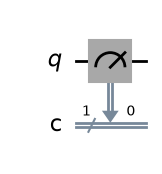

In [12]:
circuito_medida_0 = QuantumCircuit(1, 1)

circuito_medida_0.measure(0, 0)

display(circuito_medida_0.draw("mpl"))

### Responde

1. ¿Qué significa la flecha de medida?
    - Que se mide el qubit y se pasa el resultado al bit clásico.
2. ¿Dónde se almacena el resultado?
    - En el bit clásico
3. ¿Cuál debe ser el resultado?
    - 0 siempre. Porque estamos midiendo el qubit $\ket0$
4. ¿La medida es una puerta unitaria?
    - No, no es unitaria. Estamos colapasando el estado y no es reversible.

## Ejercicio 12. Medida de $|1\rangle$
Construye $|0\rangle\xrightarrow{X}|1\rangle\xrightarrow{medida}1$ y visualízalo.

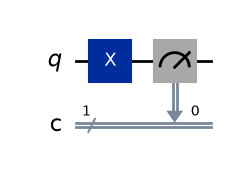

In [13]:
circuito_medida_1 = QuantumCircuit(1, 1)

circuito_medida_1.x(0)
circuito_medida_1.measure(0, 0)

display(circuito_medida_1.draw("mpl"))


### Responde

1. ¿Qué operación se aplica primero?
    - La puerta $X$
2. ¿Cómo se identifica el orden temporal?
    - De izquierda a derecha.
3. ¿Qué ocurriría si la medida apareciese antes de $X$?
    - Se mediría $\ket0$, luego se aplicaría la puerta $X$ sobre el qubit ya medido.
4. ¿El resultado clásico sería el mismo?
    - No, el resultado clásico pasaría a ser 0 en vez de 1.

## Ejercicio 13. `measure_all()`

Crea dos qubits sin bits clásicos, aplica `measure_all()`, visualiza y consulta `num_clbits`.

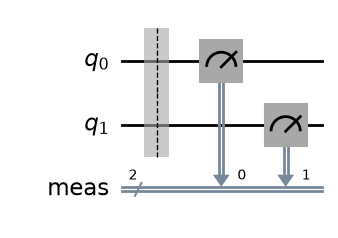

Bits clásicos: 2


In [14]:
circuito_todos = QuantumCircuit(2)

circuito_todos.measure_all()

display(circuito_todos.draw("mpl"))
print(f"Bits clásicos: {circuito_todos.num_clbits}")


### Responde

1. ¿Qué ha añadido `measure_all()`?
    - Una medida a cada qubit.
2. ¿Cuántos bits clásicos aparecen?
    - Dos
3. ¿Qué diferencia presenta respecto a `measure(0, 0)`?
    - Measure mide el qubit 0 y lo almacena en el bit clásico 0, `mientras que measure_all()` crea los bits y mide todos los qubits.
4. ¿Cuándo conviene controlar explícitamente la correspondencia?
    - Cuando hay varios qubits y se quiere solo colapsar unos y otros dejarlos todavia sin medir

# Parte E. Ejecución con Aer

## Ejercicio 14. Simulador y transpilación

Crea `AerSimulator()`. Transpila los circuitos de medida de $|0\rangle$ y $|1\rangle$ para ese backend y visualiza los resultados.

Simulador: AerSimulator('aer_simulator')


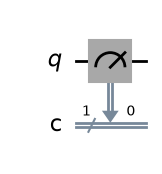

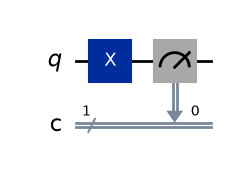

In [15]:
simulador = AerSimulator()

circuito_0_transpilado = transpile(circuito_medida_0, simulador)
circuito_1_transpilado = transpile(circuito_medida_1, simulador)

print("Simulador:", simulador)
display(circuito_0_transpilado.draw("mpl"))
display(circuito_1_transpilado.draw("mpl"))


### Responde

1. ¿El simulador es el circuito?
    - No, el simulador es el backend que ejecuta el circuito.
2. ¿Por qué se adapta un circuito al backend?
    - Porque cada backend admite un conjunto de puertas distinto.
3. ¿Qué finalidad tendrá la transpilación en hardware real?
    - Traducir el circuito a las puertas del chip físico.
4. ¿Un simulador ideal incorpora automáticamente ruido?
    - No. Habría que añadirlo voluntariamente.

## Ejercicio 15. Ejecución de $|0\rangle$
Ejecuta 1.000 shots con `seed_simulator=42`. Recupera el trabajo, el resultado y los conteos. Comprueba la suma.

In [16]:
trabajo_0 = simulador.run(circuito_0_transpilado, shots=1000, seed_simulator=42)
resultado_0 = trabajo_0.result()
conteos_0 = resultado_0.get_counts()

print("Trabajo 0:", trabajo_0)
print("Resultado 0:", resultado_0)
print("Conteos 0:", conteos_0)
print("Suma de conteos 0:", sum(conteos_0.values()))

Trabajo 0: <qiskit_aer.jobs.aerjob.AerJob object at 0x0000023EBBE2C4D0>
Resultado 0: Result(backend_name='aer_simulator', backend_version='0.18.0', job_id='572c7952-c094-448e-a7c6-81ef8bb8dc5b', success=True, results=[ExperimentResult(shots=1000, success=True, meas_level=2, data=ExperimentResultData(counts={'0x0': 1000}), header={'creg_sizes': [['c', 1]], 'global_phase': 0.0, 'memory_slots': 1, 'n_qubits': 1, 'name': 'circuit-56', 'qreg_sizes': [['q', 1]], 'metadata': {}}, status=DONE, seed_simulator=42, metadata={'batched_shots_optimization': False, 'required_memory_mb': 0, 'method': 'stabilizer', 'active_input_qubits': [0], 'device': 'CPU', 'remapped_qubits': False, 'num_qubits': 1, 'num_clbits': 1, 'time_taken': 0.009911, 'sample_measure_time': 0.0003826, 'input_qubit_map': [[0, 0]], 'max_memory_mb': 16325, 'measure_sampling': True, 'noise': 'ideal', 'parallel_shots': 1, 'parallel_state_update': 6, 'runtime_parameter_bind': False, 'num_bind_params': 1, 'fusion': {'enabled': False}},

### Responde

1. ¿Qué representa el trabajo?
    - La ejecucion que se manda al simulador.
2. ¿Qué devuelve `result()`?
    - Un objeto con toda la información de la ejecucion.
3. ¿Qué devuelve `get_counts()`?
    - Un diccionario con las cadenas de bits medidas y las veces que ha salido cada una.
4. ¿Cuánto suman los conteos?
    - 1000. La cantidad de shots ejecutados.
5. ¿Por qué el resultado es determinista?
    - Porque el qubit está en $\ket0$ y siempre va a medir 0.

## Ejercicio 16. Ejecución de $|1\rangle$
Ejecuta 10, 100, 1.000 y 10.000 shots. Para cada caso calcula conteos y frecuencias.

In [17]:
shots_estudiados_determinista = [10, 100, 1_000, 10_000]
resultados_deterministas = []

for shots in shots_estudiados_determinista:
    trabajo = simulador.run(circuito_1_transpilado, shots=shots, seed_simulator=42)
    conteos = trabajo.result().get_counts()
    n_0 = conteos.get("0", 0)
    n_1 = conteos.get("1", 0)
    resultados_deterministas.append((shots, n_0, n_1, n_0/shots, n_1/shots))
    print(f"Shots={shots:<6} conteos: {conteos} f(0)={n_0/shots:.2f} P(1)={n_1/shots:.2f}")

Shots=10     conteos: {'1': 10} f(0)=0.00 P(1)=1.00
Shots=100    conteos: {'1': 100} f(0)=0.00 P(1)=1.00
Shots=1000   conteos: {'1': 1000} f(0)=0.00 P(1)=1.00
Shots=10000  conteos: {'1': 10000} f(0)=0.00 P(1)=1.00


### Responde

1. ¿Por qué conviene utilizar `get()`?
    - Porque si un resultado no aparece, la clave no existirá en el diccionario.
2. ¿Cambia la distribución al aumentar los shots?
    - No, porque nos encontramos en $\ket1$ y siempre va a dar 1.
3. ¿Aporta información nueva usar 10.000 shots en este caso?
    - No, el resultado será el mismo.
4. ¿Aparece incertidumbre estadística en el simulador ideal?
    - No, no hay dispersión.

# Parte F. Conteos e histogramas

## Ejercicio 17. Función de ejecución

Implementa una función que valide `shots`, transpile, ejecute y devuelva conteos.

In [18]:
def ejecutar_con_shots(circuito, shots=1000, semilla=42):
    """Transpila y ejecuta un circuito con medidas."""
    if not isinstance(circuito, QuantumCircuit):
        raise ValueError("El argumento 'circuito' debe ser un objeto QuantumCircuit.")
    if isinstance(shots, bool) or not isinstance(shots, int) or shots <= 0:
        raise ValueError("El argumento 'shots' debe ser un entero positivo.")

    sim = AerSimulator()
    circuito_t= transpile(circuito, sim)
    resultado = sim.run(circuito_t, shots=shots, seed_simulator=semilla).result()
    return resultado.get_counts()


print(f"Medida de |0>: {ejecutar_con_shots(circuito_medida_0)}")
print(f"Medida de |1>: {ejecutar_con_shots(circuito_medida_1)}")

Medida de |0>: {'0': 1000}
Medida de |1>: {'1': 1000}


## Ejercicio 18. Frecuencias

Implementa una función que convierta conteos en frecuencias y rechace diccionarios vacíos, conteos negativos, no enteros o con total cero.

In [19]:
def calcular_frecuencias(conteos):
    """Convierte un diccionario de conteos en frecuencias relativas."""
    if not isinstance(conteos, dict) or len(conteos) == 0:
        raise ValueError("El argumento 'conteos' debe ser un diccionario no vacío.")
    for clave, valor in conteos.items():
        if isinstance(valor, bool) or not isinstance(valor, (int, np.integer)) or valor < 0:
            raise ValueError(f"El valor para la clave '{clave}' debe ser un entero no negativo.")

    total = sum(conteos.values())
    if total == 0:
        raise ValueError("El total de conteos es cero, no se pueden calcular frecuencias.")

    return {clave: valor / total for clave, valor in conteos.items()}

print(calcular_frecuencias({"0": 250, "1": 750}))

{'0': 0.25, '1': 0.75}


### Responde

1. ¿Qué diferencia existe entre conteo y frecuencia?
    - El conteo es el número de veces que sale un resultado y la frecuencia es el conteo entre el número de shots ejecutados.
2. ¿Qué deben sumar las frecuencias?
    - 1 siempre
3. ¿Equivale una frecuencia a una amplitud?
    - No, solo se estima la probabilidad.
4. ¿Puede recuperarse el signo de una amplitud a partir de conteos?
    - No, porque es el modulo al cuadrado asi que se pierde el signo

## Ejercicio 19. Histogramas
Representa por separado los conteos de $|0\rangle$ y $|1\rangle$ y después ambos en una misma figura con leyenda.

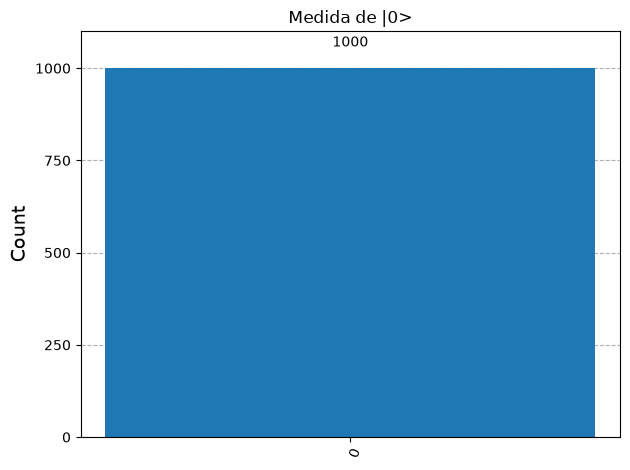

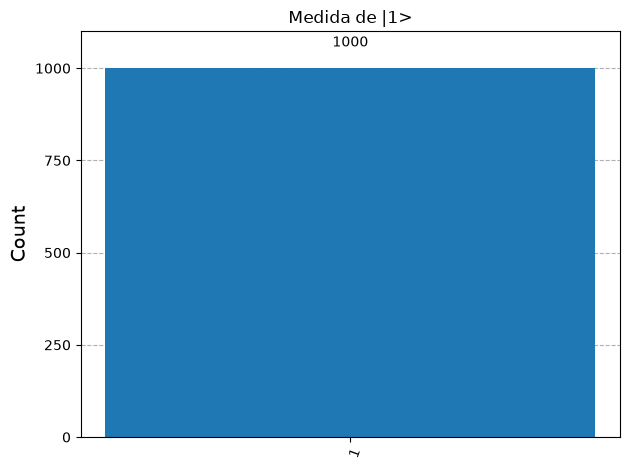

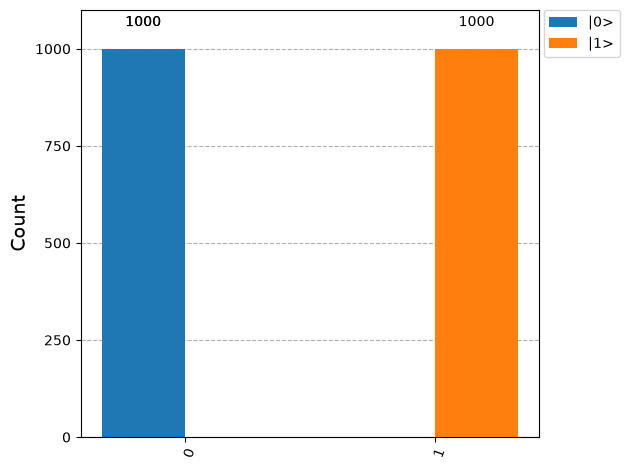

In [20]:
conteos_1 = ejecutar_con_shots(circuito_medida_1, shots=1000, semilla=42)

display(plot_histogram(conteos_0, title="Medida de |0>"))
display(plot_histogram(conteos_1, title="Medida de |1>"))
display(plot_histogram([conteos_0, conteos_1], legend=["|0>", "|1>"]))

### Responde

1. ¿Qué información representa el histograma?
    - Cuántas veces ha salido cada resultado de la medida.
2. ¿Muestra el circuito o el vector de estado?
    - No, ninguna.
3. ¿Muestra amplitudes o fases?
    - Tampoco.

# Parte G. Simulación exacta y muestreo

## Ejercicio 20. Primera superposición

Crea un circuito con una puerta $H$, obtén su vector y compáralo con $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$. Muestra probabilidades exactas.

In [21]:
circuito_plus = QuantumCircuit(1)

circuito_plus.h(0)

estado_plus = Statevector.from_instruction(circuito_plus)
ket_plus_numpy = np.array([1 / np.sqrt(2), 1 / np.sqrt(2)], dtype=complex)

print(f"Vector del estado |+>: {estado_plus.data}")
print(f"|+> en NumPy: {ket_plus_numpy}")
print(f"Coincide con |+>: {np.allclose(estado_plus.data, ket_plus_numpy)}")
print(f"Probabilidades de |+>: {estado_plus.probabilities()}")
print(f"Probabilidades de |+> (diccionario): {estado_plus.probabilities_dict()}")

Vector del estado |+>: [0.70711+0.j 0.70711+0.j]
|+> en NumPy: [0.70711+0.j 0.70711+0.j]
Coincide con |+>: True
Probabilidades de |+>: [0.5 0.5]
Probabilidades de |+> (diccionario): {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


## Ejercicio 21. Medida de la superposición

Crea una copia, añade medidas y ejecútala con 10, 100, 1.000 y 10.000 shots. Calcula $f(0)$, $f(1)$ y $|f(0)-1/2|$.

In [22]:
circuito_plus_medida = circuito_plus.copy()
circuito_plus_medida.measure_all()

shots_superposicion = [10, 100, 1_000, 10_000]
resultados_superposicion = []

print(f"{'Shots':<10}{'Conteos':<25}{'f(0)':<10}{'f(1)':<14}{'|f(0)-0.5|'}")
for shots in shots_superposicion:
    conteos = ejecutar_con_shots(circuito_plus_medida, shots)
    frecuencias = calcular_frecuencias(conteos)
    f0 = frecuencias.get("0", 0)
    f1 = frecuencias.get("1", 0)
    error = abs(f0 - 0.5)
    resultados_superposicion.append((shots, conteos, f0, f1, error))
    print(f"{shots:<10}{str(dict(conteos)):<25}{f0:<10f}{f1:<15f}{error:.4f}")

Shots     Conteos                  f(0)      f(1)          |f(0)-0.5|
10        {'0': 5, '1': 5}         0.500000  0.500000       0.0000
100       {'0': 49, '1': 51}       0.490000  0.510000       0.0100
1000      {'0': 514, '1': 486}     0.514000  0.486000       0.0140
10000     {'1': 5079, '0': 4921}   0.492100  0.507900       0.0079


### Responde

1. ¿Coinciden exactamente frecuencias y probabilidades?
    - No exactamente, fluctuan alrededor de 0,5.
2. ¿Qué sucede normalmente al aumentar los shots?
    - El error suele disminuir y las frecuencias se acercan a la probabilidad exacta.
3. ¿Debe disminuir estrictamente el error en cada fila?
    - No. Siempre existe el azar.
4. ¿Qué diferencia hay respecto a $|0\rangle$ y $|1\rangle$?
    - Con $\ket0$ siempre saldra 0 y con $\ket1$ siempre 1.
5. ¿Se conserva la fase en los conteos?
    - No, se pierde.


## Ejercicio 22. Gráfica de convergencia

Representa shots frente a frecuencia de 0, con eje horizontal logarítmico y una línea teórica en 0,5. Interpreta la gráfica.

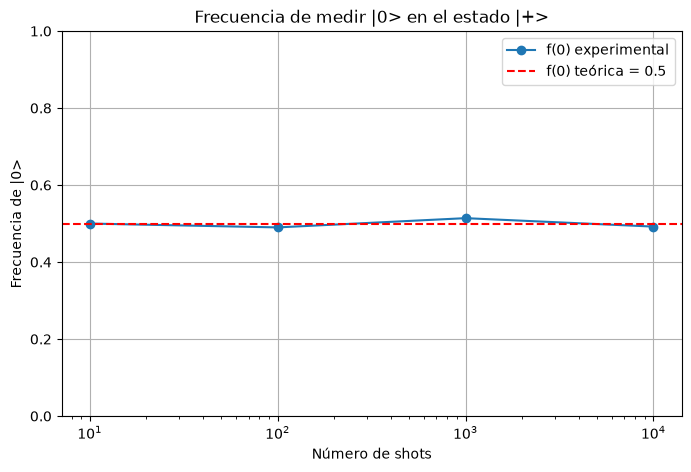

In [23]:
shots_x = [r[0] for r in resultados_superposicion]
f0_y = [r[2] for r in resultados_superposicion]

plt.figure(figsize=(8, 5))
plt.plot(shots_x, f0_y, 'o-', label='f(0) experimental')
plt.axhline(0.5, color='r', linestyle='--', label='f(0) teórica = 0.5')
plt.xscale('log')
plt.ylim(0, 1)
plt.xlabel('Número de shots')
plt.ylabel('Frecuencia de |0>')
plt.title('Frecuencia de medir |0> en el estado |+>')
plt.legend()
plt.grid(True)
plt.show()

**Interpretación:** Con pocos shots la frecuencia de 0 coincide exactamente con 0,5 (la real), pero podría perfectamente no ser así, esto depende de la seed que usemos. Al aumentar los shots podemos ver como el valor experimental fluctua alrededor del valor real. La tendencia general es de converger al valor real.

## Ejercicio 23. Comparación exacta y experimental

Con 10.000 shots, construye una tabla con resultado, amplitud, probabilidad exacta, conteo y frecuencia.

In [24]:
shots_23 = 10000
conteos_23 = ejecutar_con_shots(circuito_plus_medida, shots_23)
frecuencias_23 = calcular_frecuencias(conteos_23)

print(f"{'Resultado':<10}{'Amplitud':<10}{'Probabilidad exacta':<22}{'Conteos':<10}{'Frecuencia':<10}")
for i, resultado in enumerate(["0", "1"]):
    amplitud = estado_plus.data[i].real
    prob = estado_plus.probabilities()[i]
    print(f"{resultado:<10}{amplitud:<10f}{prob:<22f}{conteos_23.get(resultado, 0):<10}{frecuencias_23.get(resultado, 0):<10f}")

Resultado Amplitud  Probabilidad exacta   Conteos   Frecuencia
0         0.707107  0.500000              4921      0.492100  
1         0.707107  0.500000              5079      0.507900  


### Responde

1. ¿Qué columnas proceden de `Statevector`?
    - La amplitud y probabilidad exacta.
2. ¿Cuáles requieren medida?
    - El conteo y la frecuencia.
3. ¿Cuál conserva información de fase?
    - La amplitud.
4. ¿Por qué los conteos no reconstruyen el estado completo?
    - Solo dan probabilidades aproximadas y se pierde la fase

# Parte H. Circuitos de dos qubits

## Ejercicio 24. Estado inicial

Crea dos qubits, obtén el vector y el diccionario de probabilidades, y comprueba que representan $|00\rangle$.

In [25]:
circuito_00 = QuantumCircuit(2)
estado_00 = Statevector.from_instruction(circuito_00)

print(f"Vector: {estado_00.data}")
print(f"Dimensión: {estado_00.dim}")
print(f"Probabilidades: {estado_00.probabilities_dict()}")
print(f"Es |00>?: {np.allclose(estado_00.data, [1,0,0,0])}")

Vector: [1.+0.j 0.+0.j 0.+0.j 0.+0.j]
Dimensión: 4
Probabilidades: {np.str_('00'): np.float64(1.0)}
Es |00>?: True


### Responde

1. ¿Cuántas amplitudes contiene?
    - Cuatro
2. ¿Por qué son cuatro?
    - Porque cada qubit tiene 2 estados posibles y hay 2 qubits.
3. ¿Cuál es el orden de la base?
    - $\ket{00}$, $\ket{01}$, $\ket{10}$ y $\ket{11}$ 
4. ¿Qué dimensión tendrá un estado de tres qubits?
    - $2^3=8$

## Ejercicio 25. Base computacional de dos qubits
Construye circuitos para $|00\rangle$, $|01\rangle$, $|10\rangle$ y $|11\rangle$. Dibuja cada uno y muestra su vector y `probabilities_dict()`.

|00>:


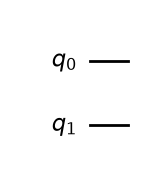

Vector: [1.+0.j 0.+0.j 0.+0.j 0.+0.j]
Probabilidades: {np.str_('00'): np.float64(1.0)}

|01>:


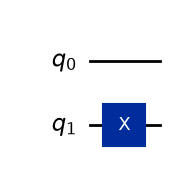

Vector: [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
Probabilidades: {np.str_('10'): np.float64(1.0)}

|10>:


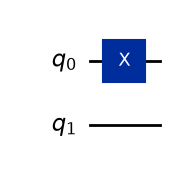

Vector: [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
Probabilidades: {np.str_('01'): np.float64(1.0)}

|11>:


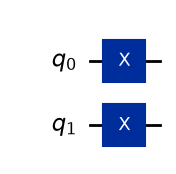

Vector: [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
Probabilidades: {np.str_('11'): np.float64(1.0)}



In [26]:
circuito_01 = QuantumCircuit(2)
circuito_01.x(1)

circuito_10 = QuantumCircuit(2)
circuito_10.x(0)

circuito_11 = QuantumCircuit(2)
circuito_11.x(0)
circuito_11.x(1)


circuitos_base_2q = {
    "|00>": circuito_00,
    "|01>": circuito_01,
    "|10>": circuito_10,
    "|11>": circuito_11,
}

for nombre, circuito in circuitos_base_2q.items():
    estado = Statevector.from_instruction(circuito)
    print(f"{nombre}:")
    display(circuito.draw("mpl"))
    print(f"Vector: {estado.data}")
    print(f"Probabilidades: {estado.probabilities_dict()}")
    print()

## Ejercicio 26. Orden de bits

Aplica `x(0)` a dos qubits. Muestra el vector y el diccionario de probabilidades.

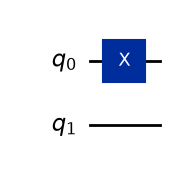

Vector: [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
Probabilidades: {np.str_('01'): np.float64(1.0)}


In [27]:
circuito_orden = QuantumCircuit(2)

circuito_orden.x(0)

estado_orden = Statevector.from_instruction(circuito_orden)

display(circuito_orden.draw("mpl"))
print(f"Vector: {estado_orden.data}")
print(f"Probabilidades: {estado_orden.probabilities_dict()}")


### Responde

1. ¿Por qué aparece `"01"` y no `"10"`?
    - Porque Qiskit escribe las cadenas con el qubit 0 a la derecha. 
2. ¿Qué valores tienen $q_0$ y $q_1$?
    - $q_0=1$ y $q_1=0$.
3. ¿En qué orden se muestran las cadenas?
    - $q_1q_0$
4. ¿Cuál es el orden del vector de amplitudes?
    - El mismo orden que las cadenas: las posiciones son 00, 01, 10, 11. El vector es (0,1,0,0), asi que la amplitud 1 está en la posición "01".

## Ejercicio 27. Medida de dos qubits

Para los cuatro estados de la base, crea copias con dos bits clásicos, mide cada qubit en el bit del mismo índice y ejecuta 1.000 shots.

In [28]:
conteos_base_2q = {}

for nombre, circuito in circuitos_base_2q.items():
    c_medida = circuito.copy()
    c_medida.measure_all()
    conteos = ejecutar_con_shots(c_medida, shots=1000)
    conteos_base_2q[nombre] = conteos
    print(f"Conteos para {nombre}: {conteos}")

Conteos para |00>: {'00': 1000}
Conteos para |01>: {'10': 1000}
Conteos para |10>: {'01': 1000}
Conteos para |11>: {'11': 1000}


## Ejercicio 28. Intercambio de bits clásicos
Prepara $|01\rangle$ y compara la medida directa `q0→c0, q1→c1` con la medida intercambiada `q0→c1, q1→c0`.

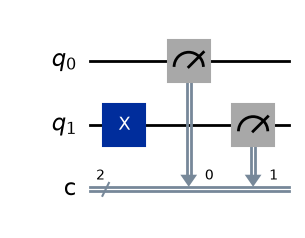

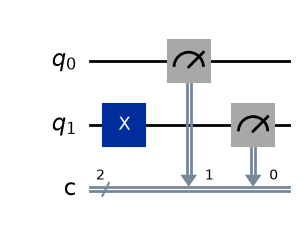

Medida directa (q0->c0, q1->c1): {'10': 1000}
Medida intercambiada (q0->c1, q1->c0): {'01': 1000}


In [29]:
base_01 = QuantumCircuit(2, 2)
base_01.x(1)

directa = base_01.copy()
directa.measure(0, 0)
directa.measure(1, 1)

intercambiada = base_01.copy()
intercambiada.measure(0, 1)
intercambiada.measure(1, 0)

display(directa.draw("mpl"))
display(intercambiada.draw("mpl"))

print("Medida directa (q0->c0, q1->c1):", ejecutar_con_shots(directa, 1000))
print("Medida intercambiada (q0->c1, q1->c0):", ejecutar_con_shots(intercambiada, 1000))

### Responde

1. ¿Cambia el estado anterior a la medida?
    - No, el estado es el mismo.
2. ¿Cambia la cadena clásica?
    - Si, pasa de "01" a "10".
3. ¿Qué demuestra el experimento?
    - Que el resultado clásico depende de que bit guarde cada medida.
4. ¿Por qué debe revisarse el mapeo entre qubits y bits?
    - Para no malinterpretar resultados.

# Parte I. Interpretación conceptual

## Ejercicio 29. Clasificación

Clasifica y justifica: `QuantumCircuit(2,2)`, `Statevector.from_instruction(c)`, `estado.data`, `estado.probabilities()`, `measure()`, `"01"`, `{"00":492,"11":508}`, `492/1000`, `plot_histogram()` y `simulador.run()`.

**Respuesta:**
   - `QuantumCircuit(2,2)`: Construccion de un circuito con 2 qubits y 2 bits clásicos. No está ejecutado.
  
   - `Statevector.from_instruction(c)`: simulación exacta del circuito c. Devuelve el estado final del circuito.
   - `estado.data`: amplitudes exactas en un array de Numpy con numeros complejos.
   - `estado.probabilities()`: probabilidades exactas calculadas con las amplitudes.
   - `measure()` función que mide el circuito, no es unitaria.
   - `"01"`: cadena de bits, un resultado de medida.
   - `{"00":492,"11":508}`: conteos de un resultado experimental con 1000 shots minimo.
   - `492/1000`: frecuencia que estima la probabilidad. Es experimental.
   - `plot_histogram()`: visualizacion de conteos/probabilidades.
   - `simulador.run()`: ejecución del circuito en el backend.

## Ejercicio 30. Verdadero o falso

Justifica:

1. Crear un circuito lo ejecuta inmediatamente.
2. Los qubits comienzan por defecto en $|0\rangle$.
3. Un bit clásico puede contener una superposición.
4. Declarar bits clásicos añade medidas.
5. `Statevector.data` contiene amplitudes.
6. `probabilities_dict()` devuelve conteos.
7. Cada shot incluye una nueva preparación.
8. El histograma muestra amplitudes.
9. La transpilación adapta el circuito al backend.
10. Dos circuitos distintos pueden producir el mismo estado final.
11. Probabilidades iguales implican amplitudes iguales.
12. Qiskit muestra $q_0$ a la izquierda de las cadenas.
13. `x(0)` sobre dos qubits prepara $|01\rangle$.
14. Un simulador ideal incluye ruido automáticamente.
15. La medida puede eliminar información de fase.

**Respuesta:**

1. Falso, solo se construye.
2. Verdadero.
3. Falso, solo vale 0 o 1.
4. Falso, declarar bits no añade medidas.
5. Verdadero.
6. Falso, devuelve probabilidades exactas, no conteos.
7. Verdadero.
8. Falso, muestra conteos o probabilidades.
9. Verdadero.
10. Verdadero
11. Falso, pueden tener distinta fase.
12. Falso, aparece a la derecha.
13. Verdadero.
14. Falso, hay que añadirlo con un modelo de ruido.
15. Verdadero.


# Reto avanzado. Analizador de circuitos

Implementa una función que reciba un circuito sin medidas y devuelva el vector, probabilidades exactas, una copia con medidas, conteos y frecuencias. Debe validar el tipo, los shots y que el circuito no contenga medidas.

In [30]:
def analizar_circuito(circuito_sin_medidas, shots=1000, semilla=42):
    """Analiza exactamente un circuito y simula después sus medidas."""
    if not isinstance(circuito_sin_medidas, QuantumCircuit):
        raise TypeError("circuito_sin_medidas debe ser un QuantumCircuit")
    if isinstance(shots, bool) or not isinstance(shots, int) or shots <=0:
        raise ValueError("shots debe ser un entero positivo")
    if any(inst.operation.name == "measure" for inst in circuito_sin_medidas.data):
            raise ValueError("el circuito no puede contener medidas")

    estado = Statevector.from_instruction(circuito_sin_medidas)
    probabilidades_exactas = estado.probabilities_dict()

    circuito_medido = circuito_sin_medidas.copy()
    circuito_medido.measure_all()
    conteos = ejecutar_con_shots(circuito_medido, shots, semilla)

    if sum(conteos.values()) != shots:
            raise RuntimeError("los conteos no suman el número de shots")
    
    frecuencias = calcular_frecuencias(conteos)
    
    return {
        "estado": estado,
        "probabilidades_exactas": probabilidades_exactas,
        "circuito_medido": circuito_medido,
        "conteos": conteos,
        "frecuencias": frecuencias,
    }


circuitos_prueba = {}

c_vacio = QuantumCircuit(1)
circuitos_prueba["Vacío"] = c_vacio

c_x = QuantumCircuit(1)
c_x.x(0)
circuitos_prueba["X"] = c_x

c_xx = QuantumCircuit(1)
c_xx.x(0)
c_xx.x(0)
circuitos_prueba["XX"] = c_xx

c_h = QuantumCircuit(1)
c_h.h(0)
circuitos_prueba["H"] = c_h

circuitos_prueba["|01>"] = circuito_01

for nombre, c in circuitos_prueba.items():
    r = analizar_circuito(c)
    print(nombre)
    print("  Vector:", r["estado"].data)
    print("  Probabilidades exactas:", r["probabilidades_exactas"])
    print("  Conteos:", dict(r["conteos"]))
    print("  Frecuencias:", r["frecuencias"])

Vacío
  Vector: [1.+0.j 0.+0.j]
  Probabilidades exactas: {np.str_('0'): np.float64(1.0)}
  Conteos: {'0': 1000}
  Frecuencias: {'0': 1.0}
X
  Vector: [0.+0.j 1.+0.j]
  Probabilidades exactas: {np.str_('1'): np.float64(1.0)}
  Conteos: {'1': 1000}
  Frecuencias: {'1': 1.0}
XX
  Vector: [1.+0.j 0.+0.j]
  Probabilidades exactas: {np.str_('0'): np.float64(1.0)}
  Conteos: {'0': 1000}
  Frecuencias: {'0': 1.0}
H
  Vector: [0.70711+0.j 0.70711+0.j]
  Probabilidades exactas: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
  Conteos: {'0': 514, '1': 486}
  Frecuencias: {'0': 0.514, '1': 0.486}
|01>
  Vector: [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
  Probabilidades exactas: {np.str_('10'): np.float64(1.0)}
  Conteos: {'10': 1000}
  Frecuencias: {'10': 1.0}


### Responde

1. ¿Qué parte es exacta?
    - El vector de estado y las probabilidades exactas
2. ¿Qué parte depende de los shots?
    - Los conteos y las frecuencias
3. ¿Qué información desaparece en los conteos?
    - La fase y amplitudes
4. ¿Por qué se conserva el circuito original sin medidas?
    - Para que no colapse el original y se pueda seguir reutilizando
5. ¿Cómo comprobarías la coherencia entre conteos y shots?
    - Comprobando que la suma de conteos es igual a la de shots.

# Pruebas mínimas

Descomenta estas pruebas al completar la práctica y añade casos inválidos.

In [31]:
assert circuito_0.num_qubits == 1
assert circuito_0.num_clbits == 0
assert np.allclose(estado_0.data, [1, 0])
assert np.allclose(estado_1.data, [0, 1])
assert np.allclose(estado_xx.data, [1, 0])
assert np.allclose(X_numpy @ ket_0_numpy, estado_1.data)
assert sum(conteos_0.values()) == 1000
assert conteos_0.get("0", 0) == 1000
assert np.allclose(estado_plus.probabilities(), [0.5, 0.5])

# frecuencias
assert calcular_frecuencias({"0": 250, "1": 750}) == {"0": 0.25, "1": 0.75}
assert np.isclose(sum(calcular_frecuencias({"0": 3, "1": 7}).values()), 1)

# dos qubits
assert np.allclose(estado_00.data, [1, 0, 0, 0])
assert np.allclose(estado_orden.data, [0, 1, 0, 0])
assert np.isclose(estado_orden.probabilities_dict()["01"], 1)

# shots inválidos
for shots_invalidos in [0, -5, 2.5]:
    try:
        ejecutar_con_shots(circuito_medida_0, shots_invalidos)
        assert False, f"shots={shots_invalidos} debería dar error"
    except (ValueError, TypeError):
        pass

# conteos inválidos
for conteos_invalidos in [{}, {"0": -1, "1": 5}, {"0": 1.5}, {"0": 0, "1": 0}]:
    try:
        calcular_frecuencias(conteos_invalidos)
        assert False, f"{conteos_invalidos} debería dar error"
    except (ValueError, TypeError):
        pass


try:
    analizar_circuito(circuito_medida_0)
    assert False, "un circuito con medidas debería dar error"
except (ValueError, TypeError):
    pass

try:
    analizar_circuito("no es un circuito")
    assert False, "un string debería dar error"
except (ValueError, TypeError):
    pass

try:
    analizar_circuito(c_h, shots=0)
    assert False, "shots=0 debería dar error"
except (ValueError, TypeError):
    pass

n_puertas_antes = len(c_h.data)
analizar_circuito(c_h)
assert len(c_h.data) == n_puertas_antes
assert all(inst.operation.name != "measure" for inst in c_h.data)

print("Todas las pruebas han pasado")

Todas las pruebas han pasado
